# B3 monthly strategy: end to end workflow

Every step calls the functions in `src/`. Set `MODE = 'download'` to fetch the latest days
first, or keep `'file'` to work from the parquet files already on disk.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

import data_load, transform as T, train, simulate as S
from config import TARGET, MODEL_DIR, DATA_DIR

MODE = 'file'

## 1. Data

In [2]:
raw = data_load.load_all() if MODE == 'download' else data_load.read_raw()
for k, v in raw.items():
    print(f'{k:8s} {len(v):>7} rows  {v.Date.min():%Y-%m-%d} .. {v.Date.max():%Y-%m-%d}')

stocks    204957 rows  2005-01-03 .. 2026-10-20
indexes     5679 rows  2005-01-03 .. 2026-10-20
bcb        14131 rows  2005-01-01 .. 2026-10-20
fred       11631 rows  2005-01-01 .. 2026-10-16


## 2. One dataframe and the feature sets

In [3]:
df = T.build_dataset(raw) if MODE == 'download' else T.load()
NUMERICAL, TO_PREDICT = T.feature_sets(df)
_, DUMMIES = T.add_dummies(df.head(1000))
print(df.shape)
print('TO_PREDICT', TO_PREDICT)
print('NUMERICAL', len(NUMERICAL), '| CATEGORICAL', T.CATEGORICAL)
df.groupby('split').Date.agg(['min', 'max', 'count'])

(198427, 185)
TO_PREDICT ['growth_future_20d', 'is_beating_cdi_20d_future']
NUMERICAL 168 | CATEGORICAL ['Month', 'Weekday', 'Ticker', 'Sector', 'rsi_bin', 'vol_regime', 'selic_regime']


,min,max,count
split,,,
test,2022-01-03,2026-10-20,47960
train,2006-01-02,2018-12-28,120747
validation,2019-01-02,2021-12-30,29720


## 3. EDA

In [4]:
print(df.groupby('split')[TARGET].mean().round(3))
df.growth_future_20d.describe(percentiles=[.05, .25, .5, .75, .95]).round(4)

split
test          0.492
train         0.496
validation    0.539
Name: is_beating_cdi_20d_future, dtype: float64

count    197422.0000
mean          1.0135
std           0.1080
min           0.2300
5%            0.8544
25%           0.9541
50%           1.0081
75%           1.0694
95%           1.1820
max           3.0000
Name: growth_future_20d, dtype: float64

In [5]:
lab = df[df[TARGET].notna()]
corr = lab[NUMERICAL + [TARGET]].corr()[TARGET].drop(TARGET)
corr.reindex(corr.abs().sort_values(ascending=False).index).head(20).round(3)

ln_volume             0.095
adxr                 -0.083
mfi                   0.080
ultosc                0.078
plus_di              -0.075
selic_change_90d     -0.074
adx                  -0.072
slowd                 0.060
vix                   0.059
growth_ibov_90d      -0.057
corr_ibov_60d         0.056
aroon_1              -0.056
slowk                 0.052
unemployment          0.052
growth_usdbrl_90d     0.050
growth_wti_oil_90d   -0.048
DGS10                -0.046
ipca_12m             -0.045
SMA20                -0.041
SMA10                -0.040
Name: is_beating_cdi_20d_future, dtype: float64

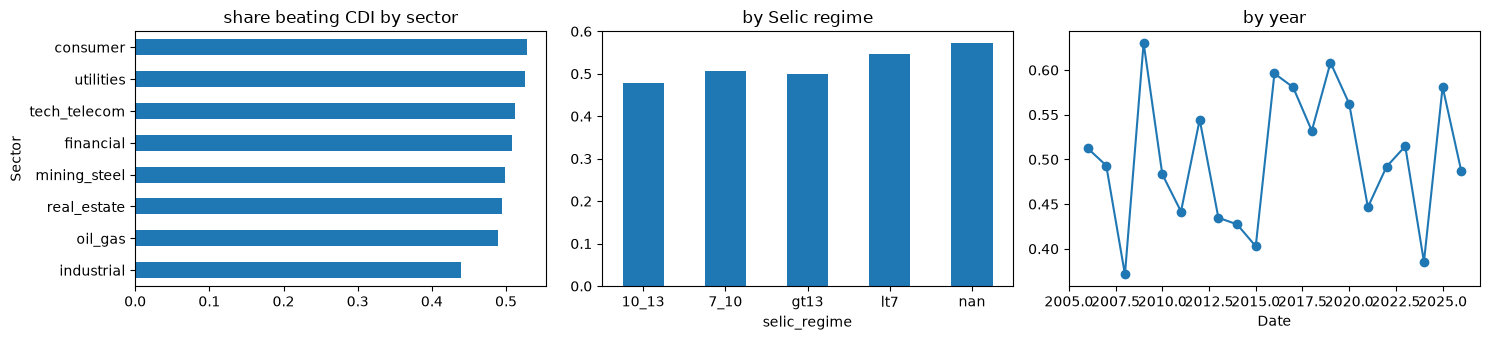

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
lab.groupby('Sector')[TARGET].mean().sort_values().plot.barh(ax=ax[0], title='share beating CDI by sector')
lab.groupby('selic_regime')[TARGET].mean().plot.bar(ax=ax[1], title='by Selic regime', rot=0)
lab.groupby(lab.Date.dt.year)[TARGET].mean().plot(ax=ax[2], title='by year', marker='o')
plt.tight_layout(); plt.show()

## 4. Models

In [7]:
rep = json.load(open(MODEL_DIR / 'tuning_report.json'))
tree = pd.DataFrame(rep['tree']).T.round(4); forest = pd.DataFrame(rep['forest']).T.round(4); boost = pd.DataFrame(rep['xgb']).T.round(4)
display(tree.sort_values('auc', ascending=False).head(5)); display(forest.sort_values('auc', ascending=False)); display(boost.sort_values('auc', ascending=False))

,auc,precision
4,0.5494,0.6089
2,0.5270,0.5757
14,0.5115,0.5457
11,0.5111,0.5518
13,0.5074,0.5464


,auc,precision,seconds
"(7, 100)",0.5472,0.5580,3.0
"(7, 50)",0.5400,0.5603,2.0
"(10, 50)",0.5219,0.5549,2.0
"(13, 50)",0.5168,0.5512,3.0
"(16, 100)",0.5109,0.5517,6.0
"(13, 100)",0.5086,0.5503,5.0
"(5, 100)",0.5058,0.5550,3.0
"(5, 50)",0.4992,0.5391,1.0
"(10, 100)",0.4975,0.5526,4.0
"(16, 50)",0.4936,0.5340,3.0


,auc,precision,rounds
"(4, 0.1)",0.5393,0.5684,118.0
"(3, 0.1)",0.5341,0.5639,80.0
"(3, 0.03)",0.5339,0.5558,2.0
"(7, 0.03)",0.5288,0.5602,7.0
"(4, 0.03)",0.5274,0.5646,34.0
"(5, 0.03)",0.5254,0.5583,38.0
"(7, 0.1)",0.5241,0.5534,64.0
"(5, 0.1)",0.5239,0.5486,77.0


In [8]:
params = train.load_params()
out, params, _, importance = train.run(df, tune=False, params=params)
print(params)
importance.head(20).round(4)

{'tree_depth': 4, 'rf_depth': 7, 'rf_n': 100, 'xgb_depth': 4, 'xgb_eta': 0.1, 'xgb_rounds': 118, 'rf_threshold': np.float64(0.56), 'xgb_threshold': np.float64(0.63)}


selic_change_90d     0.0464
ipca_12m             0.0452
vix                  0.0413
igpm_12m             0.0337
DGS10                0.0326
growth_ibov_90d      0.0301
us_curve_10y_2y      0.0285
natr                 0.0268
real_rate            0.0253
mfi                  0.0252
FEDFUNDS             0.0240
slowd                0.0238
br_us_spread         0.0231
DGS2                 0.0230
volatility           0.0218
cdi_20d              0.0217
growth_usdbrl_90d    0.0215
selic                0.0213
atr                  0.0199
unemployment         0.0186
dtype: float64

In [9]:
pd.DataFrame(rep['xgb_thresholds']).query('threshold >= 0.5').round(3).head(20)

,threshold,trades,per_day,precision
0,0.50,14150,19.044,0.568
1,0.51,12551,16.892,0.568
2,0.52,11004,14.810,0.570
3,0.53,9533,12.830,0.574
4,0.54,8162,10.985,0.574
5,0.55,6861,9.234,0.577
6,0.56,5789,7.791,0.585
7,0.57,4720,6.353,0.592
8,0.58,3788,5.098,0.588
9,0.59,3041,4.093,0.596


## 5. Simulations\n\n### sim1: R$100 on every signal

In [10]:
preds = [c for c in out.columns if c.startswith('pred')]
sim1 = S.sim1_vector(out, preds)
sim1.round(3)

,prediction,count,precision,avg_per_day,net_rev,capital,CAGR
0,pred0_manual_rsi_oversold,166,0.602,1.248,529.968,2000.0,1.051
1,pred1_manual_momentum,19018,0.491,28.428,13937.438,66000.0,1.041
2,pred2_manual_cheap_selic_falling,4472,0.516,11.799,6722.134,32000.0,1.041
3,pred5_tree,29396,0.471,39.995,10967.223,80000.0,1.028
4,pred6_rf,24552,0.510,30.883,29535.360,80000.0,1.069
5,pred7_rf_rule_56,579,0.698,9.492,2414.164,30000.0,1.017
6,pred8_xgb,19225,0.523,16.320,26147.350,46000.0,1.100
7,pred9_xgb_rule_63,1000,0.546,1.980,1057.812,4000.0,1.051
8,pred10_rf_and_xgb,7,0.714,1.000,43.965,2000.0,1.005


### sim2: exact day by day simulation with reinvestment

The signals are ranked by probability and the portfolio always holds the best five
(threshold 0). Higher thresholds were tried too: on test they leave the money idle most of
the time, since the probabilities from 2022 on sit lower than in the validation years.
A random ranking is included as the baseline any model has to beat.

In [11]:
rng = np.random.default_rng(0)
out['proba_random'] = rng.random(len(out))
out['proba_lowvol'] = 1 - out.rank_volatility
out['proba_xgb_lowvol'] = out.groupby('Date').proba_xgb.rank(pct=True) + out.proba_lowvol
runs = {
    'xgb top5':                  dict(proba='proba_xgb', threshold=0, max_positions=5),
    'xgb top5 stop10':           dict(proba='proba_xgb', threshold=0, max_positions=5, stop_loss=0.10),
    'xgb top5 stop10 proba-size':dict(proba='proba_xgb', threshold=0, max_positions=5, stop_loss=0.10, sizing='proba'),
    'xgb top10':                 dict(proba='proba_xgb', threshold=0, max_positions=10),
    'xgb >= rule, top5':         dict(proba='proba_xgb', threshold=params['xgb_threshold'], max_positions=5),
    'xgb top5 vix<30':           dict(proba='proba_xgb', threshold=0, max_positions=5, regime=lambda s: s.vix < 30),
    'rf top5':                   dict(proba='proba_rf', threshold=0, max_positions=5),
    'tree top5':                 dict(proba='proba_tree', threshold=0, max_positions=5),
    'low volatility top5':       dict(proba='proba_lowvol', threshold=-1, max_positions=5),
    'xgb + low vol top5':        dict(proba='proba_xgb_lowvol', threshold=-1, max_positions=5),
    'random top5':               dict(proba='proba_random', threshold=0, max_positions=5),
}
curves, logs = {}, {}
for name, kw in runs.items():
    curves[name], logs[name] = S.sim2_exact(out, raw['stocks'], **kw)
start, end = curves[name].index[0], curves[name].index[-1]
bench, cdi = S.benchmarks(raw['indexes'], raw['bcb'], start, end)
table = pd.DataFrame({**{k: S.metrics(c.equity, cdi) for k, c in curves.items()},
                      **{k: S.metrics(v, cdi) for k, v in bench.items()}}).T
table.round(3)

,CAGR,volatility,max_drawdown,sharpe,final_multiple
xgb top5,-0.000,0.243,-0.365,-0.381,1.000
xgb top5 stop10,0.104,0.240,-0.319,0.028,1.610
xgb top5 stop10 proba-size,-0.049,0.268,-0.545,-0.512,0.784
xgb top10,0.104,0.217,-0.293,0.007,1.609
"xgb >= rule, top5",0.076,0.161,-0.204,-0.220,1.420
xgb top5 vix<30,0.070,0.236,-0.410,-0.111,1.381
rf top5,0.238,0.235,-0.251,0.515,2.782
tree top5,0.145,0.220,-0.262,0.176,1.913
low volatility top5,0.169,0.155,-0.154,0.310,2.118
xgb + low vol top5,0.184,0.170,-0.199,0.368,2.245


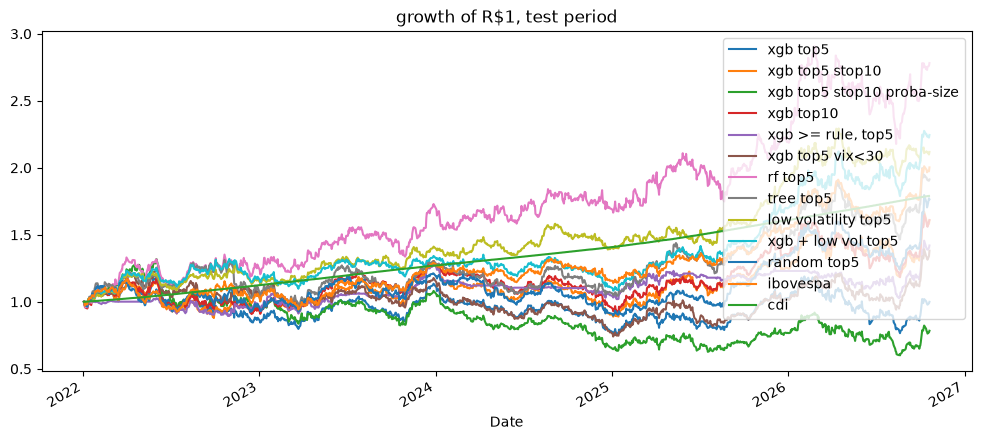

In [12]:
ax = (pd.DataFrame({k: c.equity / c.equity.iloc[0] for k, c in curves.items()})
      .join(pd.DataFrame(bench))).plot(figsize=(12, 5), title='growth of R$1, test period')
plt.show()

### Picking the strategy without looking at the test years

The table above is all test data, so choosing the winner from it would be cheating. The same
candidates are run on the validation years (2019-2021) with an xgboost trained on 2006-2018 only.

In [13]:
import xgboost as xgb
d2, X2, _, sf = train.prepare(df)
tr = (d2.split == 'train') & d2[TARGET].notna()
xp = {'objective': 'binary:logistic', 'max_depth': int(params['xgb_depth']), 'eta': params['xgb_eta'], 'subsample': 0.8,
      'colsample_bytree': 0.5, 'min_child_weight': 200, 'seed': 42, 'nthread': -1}
b = xgb.train(xp, xgb.DMatrix(X2.loc[tr, sf], label=d2.loc[tr, TARGET]), int(params['xgb_rounds']))
v = out[['Date', 'Ticker', 'split', TARGET, 'growth_future_20d', 'rank_volatility', 'proba_random', 'vix']].copy()
v['proba_xgb'] = b.predict(xgb.DMatrix(X2[sf]))
v['split'] = np.where(out.split == 'validation', 'test', 'other')
v['proba_lowvol'] = 1 - v.rank_volatility
v['proba_xgb_lowvol'] = v.groupby('Date').proba_xgb.rank(pct=True) + v.proba_lowvol
vruns = {k: kw for k, kw in runs.items() if k in ['xgb top5', 'xgb top5 stop10', 'xgb top10', 'low volatility top5', 'xgb + low vol top5', 'random top5']}
vcurves = {k: S.sim2_exact(v, raw['stocks'], **kw)[0] for k, kw in vruns.items()}
vb, vcdi = S.benchmarks(raw['indexes'], raw['bcb'], vcurves['xgb top5'].index[0], vcurves['xgb top5'].index[-1])
pd.DataFrame({**{k: S.metrics(c.equity, vcdi) for k, c in vcurves.items()}, **{k: S.metrics(x, vcdi) for k, x in vb.items()}}).T.round(3)

,CAGR,volatility,max_drawdown,sharpe,final_multiple
xgb top5,0.073,0.183,-0.423,-0.019,1.731
xgb top5 stop10,0.058,0.171,-0.399,-0.119,1.547
xgb top10,0.075,0.181,-0.411,-0.008,1.763
low volatility top5,0.052,0.151,-0.351,-0.186,1.490
xgb + low vol top5,0.079,0.153,-0.338,-0.020,1.808
random top5,0.120,0.194,-0.374,0.217,2.420
ibovespa,0.112,0.227,-0.468,0.178,2.287
cdi,0.095,0.003,0.000,1.932,2.035


In [14]:
best = 'xgb top5 stop10'
c = curves[best].equity
rolling = c.pct_change(252).dropna()
print(best, '| trades:', len(logs[best]), '| exits:', logs[best].reason.value_counts().to_dict())
print('rolling 1y return: min %.3f median %.3f max %.3f' % (rolling.min(), rolling.median(), rolling.max()))
logs[best].groupby(logs[best].exit_date.dt.year)['return'].agg(['count', 'mean', lambda r: (r > 0).mean()]).round(3)

xgb top5 stop10 | trades: 314 | exits: {'time': 253, 'stop': 61}
rolling 1y return: min -0.311 median 0.086 max 0.562


,count,mean,<lambda_0>
exit_date,,,
2022,66,-0.001,0.470
2023,63,0.027,0.571
2024,66,-0.020,0.364
2025,63,0.027,0.619
2026,56,0.030,0.625


## 6. Where the model is right and wrong

In [15]:
p = [c for c in preds if c.startswith('pred9')][0]
S.precision_by(out, p, 'Sector').round(3)

,rows,base_rate,signals,precision,avg_growth_when_signal
Sector,,,,,
financial,7074,0.514,122,0.746,1.062
utilities,9432,0.517,169,0.669,1.037
industrial,5895,0.436,58,0.655,1.055
real_estate,3537,0.499,80,0.575,0.968
oil_gas,4716,0.522,101,0.535,1.007
consumer,5895,0.466,86,0.512,1.016
mining_steel,7074,0.478,373,0.424,0.990
tech_telecom,3537,0.502,11,0.182,0.961


In [16]:
S.precision_by(out, p, 'Ticker').round(3)

,rows,base_rate,signals,precision,avg_growth_when_signal
Ticker,,,,,
BBAS3,1179,0.495,1,1.000,1.227
PETR4,1179,0.594,3,1.000,1.068
CPFE3,1179,0.513,6,1.000,1.098
GGBR4,1179,0.532,3,1.000,1.042
LREN3,1179,0.444,5,1.000,1.048
TIMS3,1179,0.539,2,1.000,1.078
MULT3,1179,0.506,23,0.913,1.054
EQTL3,1179,0.504,22,0.864,1.097
EGIE3,1179,0.493,24,0.833,1.035


In [17]:
t = out[(out.split == 'test') & out[TARGET].notna()].copy()
t['year'] = t.Date.dt.year
display(S.precision_by(t, p, 'year').round(3))
wrong = t[(t[p] == 1) & (t[TARGET] == 0)]
print('worst false positives')
wrong.sort_values('growth_future_20d').head(10)[['Date', 'Ticker', 'proba_xgb', 'growth_future_20d', 'rsi', 'vix', 'selic']]

,rows,base_rate,signals,precision,avg_growth_when_signal
year,,,,,
2023,9920,0.515,210,0.595,1.014
2025,10000,0.581,307,0.560,1.029
2026,7200,0.487,324,0.543,1.014
2022,10000,0.492,129,0.481,0.983
2024,10040,0.385,30,0.367,0.946


worst false positives


,Date,Ticker,proba_xgb,growth_future_20d,rsi,vix,selic
55849,2026-06-02,CSNA3,0.634645,0.643759,60.563431,15.770000,14.50
54853,2022-06-03,CSNA3,0.633974,0.654825,60.795716,24.790001,12.75
55847,2026-05-29,CSNA3,0.661541,0.691505,53.829338,15.320000,14.50
55850,2026-06-03,CSNA3,0.634680,0.691617,51.597854,16.059999,14.50
55846,2026-05-28,CSNA3,0.648205,0.695588,55.936049,15.740000,14.50
55848,2026-06-01,CSNA3,0.663065,0.705343,50.208950,16.049999,14.50
118005,2023-12-28,MRVE3,0.652158,0.708816,68.960758,12.470000,11.75
118006,2024-01-02,MRVE3,0.657406,0.712687,57.233621,13.200000,11.75
117998,2023-12-18,MRVE3,0.664173,0.713762,66.403361,12.560000,11.75
117996,2023-12-14,MRVE3,0.655130,0.716528,65.708649,12.480000,11.75


## 7. Signals for the next session

In [18]:
last = out[out.Date == out.Date.max()]
last.sort_values('proba_xgb', ascending=False).head(5)[['Date', 'Ticker', 'Sector', 'Close', 'proba_rf', 'proba_xgb']]

,Date,Ticker,Sector,Close,proba_rf,proba_xgb
75115,2026-10-20,EQTL3,utilities,49.840000,0.490417,0.653383
100409,2026-10-20,ITUB4,financial,49.009998,0.497272,0.631908
113927,2026-10-20,MOTV3,industrial,20.680000,0.489550,0.630901
95235,2026-10-20,ITSA4,financial,15.730000,0.495014,0.624553
123481,2026-10-20,MULT3,real_estate,38.459999,0.490417,0.623246
